## State Definition

In [21]:
import operator
from typing import Literal, List
from pydantic import BaseModel, Field 
from typing import Annotated
from typing_extensions import TypedDict
# from langgraph.graph.message import add_messages


class UserQuery(BaseModel):
    """State to manage user query"""
    query: str = Field(..., description="An user query for generation of the content")

class EnhacedQueries(BaseModel):
    """ Model structure to get the enhanced queries """
    queries: List[str] = Field(..., description="A list of enhanced queries of the given query")


class ValidatorReponses(BaseModel):
    """ Model Structure to get the relavant documents """
    relavent_indices: List[int] = Field(...,
                    description="""A list of relavent indices sorting 
                    based on highly relavent and removing irrelavent indices""")


class HiddenModelState(TypedDict):
    """State to manage the generated results from the model and
    data from youtube retrieveal
    """
    # enhanced_query: str = Field(..., description="An enhanced query of the user"
    enhanced_query: str
    enhanced_queries: list
    youtube_meta_information: Annotated[list, operator.add]
    query_type: str = Literal["factual", "analytical", "opinion"] 

class ContentState(BaseModel):
    """ State to manage the final content from different models """
    response: str = Field(..., description="A transciprtion of the all the videos")

## Structured Output

In [22]:

from langchain.output_parsers import PydanticOutputParser

enhaced_query_parser = PydanticOutputParser(pydantic_object=EnhacedQueries)
# Instruction on strucuted output
instructions_on_query_format = enhaced_query_parser.get_format_instructions()

validator_query_parser = PydanticOutputParser(pydantic_object=ValidatorReponses)
instructions_on_validator_parser = validator_query_parser.get_format_instructions()


## Prompt Definition

In [23]:
from langchain_core.messages import HumanMessage, SystemMessage

enhanced_sys_query = SystemMessage("""You are professional text enhancer to optimize the youtube results. 
You enhance the given query to clear, effective and precise query. So that it creates a effective youtube results. 

Instructions:
1. Do not halucinate.
2. Do not give any preamble.
3. Just provide a short enhanced query in a string 

""")

analyizer_sys_query = SystemMessage("""Role: You are a question classifier responsible for categorizing queries into one of three types: "opinion," "analytical," or "factual."

Instructions:

Classify the query as "opinion" if it asks for a personal belief, preference, or subjective judgment.

Classify the query as "analytical" if it requires reasoning, evaluation, or comparison of ideas, concepts, or arguments.

Classify the query as "factual" if it seeks objective information or verifiable facts.

Response: Provide only one of the following labels: "opinion," "analytical," or "factual." Do not include any additional information or explanations.
""")


message =  """Role: You are a question classifier responsible for categorizing queries into one of three types: "opinion," "analytical," or "factual."

Instructions:

1. Classify the query as "opinion" if it asks for a personal belief, preference, or subjective judgment.
2. Classify the query as "analytical" if it requires reasoning, evaluation, or comparison of ideas, concepts, or arguments.
3. Classify the query as "factual" if it seeks objective information or verifiable facts.

Response: Provide only one of the following labels: "opinion," "analytical," or "factual." Do not include any additional information or explanations.

Do not output any thinking process or intermediary steps, including "<think>". Provide only the classification label."""

analyizer_sys_query = SystemMessage(message)



opinion_sys_query = SystemMessage("""
Role: You are a digital media researcher and prompt engineer
specialized in search optimization.

Instructions:

1. Given a topic, generate a list of 5 effective YouTube
search queries in Python list format.

2. Each query should aim to uncover a different viewpoint (
e.g., ethical, political, economic, cultural, technical, etc.).

3. Include keywords that reflect contrasting
stances (e.g., support, criticism, debate, policy, impact, concern).

4. Keep queries natural, like what real users would type in YouTube search.
5. Do not explain — just return the list as Python code.

""")

analyitcal_sys_query = SystemMessage("""
Role: You are a prompt engineer and digital researcher with expertise 
in uncovering opinion-based content on YouTube.

Instructions:
1. Given a topic, generate a Python list of 5 YouTube search queries
targeting content that reflects varied opinion strategies, such as:
- Expert opinions / Thought leaders
- Influencer perspectives
- Public sentiment or street interviews
- Debates or panel discussions
- Personal experiences or storytelling

2. Use natural search phrasing for better YouTube results.
3. Output only the Python list — no explanations.

""")

validate_sys_query = SystemMessage("""I will provide you with several descriptions.
Your task is to create a concise summary based only on the data
provided in those descriptions. Do not add any external knowledge
or information beyond what is given in the descriptions. Ensure
that the summary is clear, accurate, and concise,
focusing on the key points presented.

Key Points:
 Only include indices for descriptions that are highly relevant to the query.
 Do not include descriptions that do not directly relate to the query.
 Do not provide any extra commentary, summaries, or explanations.
 Avoid hallucinations, assumptions, or extra information beyond
 the given query and descriptions
 
""")
valdiator_sys_instr = SystemMessage(instructions_on_validator_parser)
structured_output_on_strategy = SystemMessage(instructions_on_query_format)

## Youtube API

In [ ]:
from googleapiclient.discovery import build
from urllib.parse import urlparse, parse_qs


class YoutubeAPI:
    
    def get_video_id(self, youtube_url: str):
        """Extracts the video ID from a YouTube URL."""
        parsed_url = urlparse(youtube_url)
        if parsed_url.hostname in ["www.youtube.com", "youtube.com"]:
            return parse_qs(parsed_url.query).get("v", [None])[0]
        elif parsed_url.hostname == "youtu.be":
            return parsed_url.path[1:]
        return None
    
    def get_video_stats(self, video_url: str):
        # TODO create a environment variable
        api_key = ""
        video_id = self.get_video_id(video_url)
        if not video_id:
            return "Invalid YouTube URL"
    
        youtube = build("youtube", "v3", developerKey=api_key)
        request = youtube.videos().list(part="statistics,snippet", id=video_id)
        response = request.execute()
    
        if not response["items"]:
            return "Video not found"
    
        video_info = response["items"][0]
        title = video_info["snippet"]["title"]
        description = video_info["snippet"]["description"]
        
        stats = video_info["statistics"]
        youtube_information = {
            "title": title,
            "views": stats.get("viewCount", 0),
            "likes": stats.get("likeCount", 0),
            "comments": stats.get("commentCount", 0),
            # "description": description,
            "url": video_url
            }
        
        return youtube_information

    def get_videos_stats(self, videos_url: list):
        return [self.get_video_stats(video) for video in videos_url]
            

# all_youtube_information = 

video_url = "https://www.youtube.com/watch?v=dQw4w9WgXcQ"
info = YoutubeAPI().get_videos_stats([video_url])
print(info)


[{'title': 'Rick Astley - Never Gonna Give You Up (Official Music Video)', 'views': '1646096141', 'likes': '18302436', 'comments': '2387666', 'url': 'https://www.youtube.com/watch?v=dQw4w9WgXcQ'}]



## Nodes Definition

In [32]:
from typing import Dict
from pytubefix import Search
from langchain_core.output_parsers import PydanticOutputParser

class A:
    # def __init__(self):
    #     """ """
    #     self.youtube = YoutubeAPI()
        
    
    def factual_strategy(self, state: UserQuery) -> HiddenModelState:
        """ A node to generate enhanced query based on the user query given
        """
        enhanced_usr_query = HumanMessage(f"query: {state.query} ")
        model_response = llm.invoke(
                           [enhanced_sys_query] + [
                               structured_output_on_strategy
                           ] + [enhanced_usr_query])
        
        model_response = enhaced_query_parser.invoke(model_response)
        # modle_response = model_response.replace('"', '')
        return {"enhanced_queries": model_response.queries}

    
    def opinion_strategy(self, state: UserQuery) -> HiddenModelState:
        """ A node to generate opinion queries based on the user query given
        """
        opinion_usr_query = HumanMessage(f"Topic: {state.query} ")
        model_response = llm.invoke(
                           [opinion_sys_query] + [
                               structured_output_on_strategy
                           ] + [opinion_usr_query])
    
        model_response = enhaced_query_parser.invoke(model_response)
        print("=" * 100)
        print("opinion_strategy")
        print(model_response)
        # modle_response = model_response.replace('"', '')
        return {"enhanced_queries": model_response.queries}
    
    def analytical_strategy(self, state: UserQuery) -> HiddenModelState:
        """ A node to generate analytical queries based on the user query given
        """
        opinion_usr_query = HumanMessage(f"Topic: {state.query} ")
        model_response = llm.invoke(
                           [analyitcal_sys_query] + [
                               structured_output_on_strategy
                           ] + [opinion_usr_query])
        
        model_response = enhaced_query_parser.invoke(model_response)
        print("=" * 100)
        print("analytical_strategy")
        print(model_response)
        # modle_response = model_response.replace('"', '')
        return {"enhanced_queries": model_response.queries}
        
    def search_youtube(self, state: HiddenModelState) -> HiddenModelState:
        """ A node to search on youtube for the enhanced query """
        THRESHOLD = 0.020
        # search_query = state["enhanced_query"].replace('"', '')
        search_query = state["query"].replace('"', '')
        results = Search(search_query)
        
        video_urls = [video.watch_url for video in results.videos]
        
        total_views = sum([video.views for video in results.videos])
        threadshold_views = total_views * THRESHOLD
        youtube_meta_informations = ([{"url": video.watch_url,
                                      "description": video.description,
                                      "views": video.views}
                                     
                                     for video in results.videos
                                     if video.views > threadshold_views])
        # user_query = f"Query: {search_query}"
        # user_query += "\n".join([f'Description {index}: {info["description"]}'
        #                     for index, info in
        #                     enumerate(youtube_meta_informations)])
        # validator_usr_query = HumanMessage(user_query)
        # response = llm.invoke([validate_sys_query, valdiator_sys_instr, validator_usr_query])
        # response = validator_query_parser.invoke(response)
        # print("=" * 100)
        # print(response)
        sorted_meta_information = sorted(youtube_meta_informations,
                                     key=lambda meta_information: int(
                                         meta_information["views"]),
                                     reverse=True)
         
        top_n_meta_information = sorted_meta_information[:5]
        # youtube_informations = {search_query: top_n_meta_information}
        return {"youtube_meta_information": top_n_meta_information}

    # def analyzer(self, state: HiddenModelState) -> HiddenModelState:
    def analyzer(self, state: UserQuery) -> HiddenModelState:
        """ A node to analize the query and choose either factual,
        anlytical or opinion.
        """
        # query = state["enhanced_query"]
        # query = state["query"]
        query = state.query
        
        analyizer_usr_query = HumanMessage(f"query: {query}")
        model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
        # print("=" * 200)        # print(model_response)
        # print("=" * 200)        # print(model_response)
        return {"query_type": model_response }

    def strategy_condition(self, state: HiddenModelState):
        """ A condition to choose a strategy node """
        query_type = state["query_type"]
        if query_type == "factual":
            return "factual_strategy"
        elif query_type == "opinion":
            return "opinion_strategy"
        else:
            return "analytical_strategy"


            


## Model Creation

In [24]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.1",
    temperature=0,
    num_threads=29,
    num_gpu=0
 )

## Graph on Content Retrieval

In [50]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END, START
from langgraph.types import Send

from langchain_core.runnables.graph import MermaidDrawMethod

def send_queries(state: HiddenModelState):
    """Condition to send queries to youtube_searcher node"""
    # queries = eval(state["enhanced_queries"])
    queries = state["enhanced_queries"]
    return [Send("youtube_searcher", {"query": query}) for query in queries]

a = A()
# builder = StateGraph(HiddenModelState, input=UserQuery, output=ContentState)
builder = StateGraph(HiddenModelState, input=UserQuery)
builder.add_node("youtube_searcher", a.search_youtube)
builder.add_node("analyzer", a.analyzer)
builder.add_node("factual_strategy", a.factual_strategy)
builder.add_node("analytical_strategy", a.analytical_strategy)
builder.add_node("opinion_strategy", a.opinion_strategy)
# builder.add_node("dummy", a.dummy)

# builder.add_node("startegy_condition", a.strategy_condition)


builder.add_edge(START, "analyzer")
builder.add_conditional_edges("analyzer",
                              a.strategy_condition,
                              ["factual_strategy",
                               "analytical_strategy",
                               "opinion_strategy"])
builder.add_edge("factual_strategy", "youtube_searcher")
builder.add_edge("youtube_searcher", END)
builder.add_conditional_edges("opinion_strategy", send_queries, ["youtube_searcher"])
builder.add_conditional_edges("analytical_strategy", send_queries, ["youtube_searcher"])
builder.add_edge("youtube_searcher", END)


# builder.add_edge("analyzer", "query_enhancer")
# builder.add_edge("opinion_strategy", END)
# builder.add_edge("analytical_strategy", END)



# builder.add_edge(START, "query_enhancer")
# builder.add_edge("query_enhancer", END)



# builder.add_edge(START, "query_enhancer")
# builder.add_edge("query_enhancer", "analyzer")
# builder.add_edge("youtube_searcher", END)


# builder.add_edge(START, "analyzer")
# builder.add_edge("analyzer", END)

app = builder.compile()

# display(Image(app.get_graph(xray=True).draw_mermaid_png(draw_method=MermaidDrawMethod.API)))
display(Image(app.get_graph().draw_png()))

ReadTimeout: HTTPSConnectionPool(host='mermaid.ink', port=443): Read timed out. (read timeout=10)

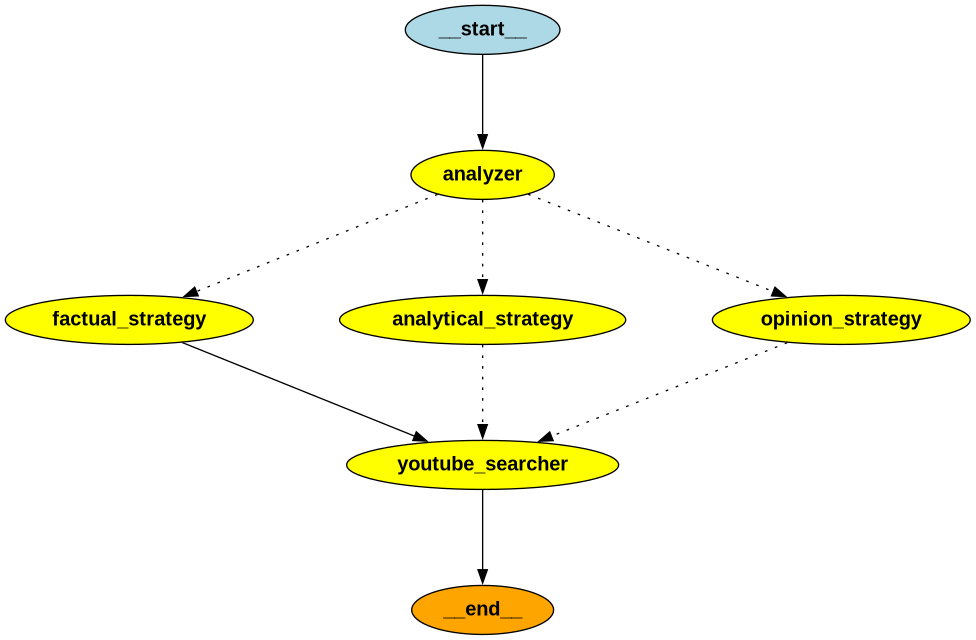

In [31]:
analytical_question = "How does the portrayal of artificial intelligence in movies compare to its actual development in technology?"
response = app.invoke({"query": analytical_question})

KeyError: 'EnhancedQueries'

In [28]:
opinion_question = "What do you think is the most impactful technological innovation of the 21st century?"
response = app.invoke({"query": opinion_question
                       })

opinion_strategy
queries=['Top tech innovations of the 21st century', 'Most influential technological advancements this century', 'Game changing technologies of the past two decades', 'Innovations that have transformed society in the 21st century', 'Technologies with the greatest potential for positive impact']


ANDROID_VR client returned: This video is not available
Switching to client: TV


In [29]:
len(response["youtube_meta_information"])

19

In [30]:
response

{'enhanced_queries': ['Top tech innovations of the 21st century',
  'Most influential technological advancements this century',
  'Game changing technologies of the past two decades',
  'Innovations that have transformed society in the 21st century',
  'Technologies with the greatest potential for positive impact'],
 'youtube_meta_information': [{'url': 'https://youtube.com/watch?v=RM717Aj_VKQ',
   'description': "Welcome to the future! 🚀 Dive into a realm of innovation with our latest video showcasing mind-blowing inventions that are on the verge of transforming our daily lives. 🌐 From cutting-edge technology to revolutionary concepts, get ready to witness the future unfold before your eyes. 🌈🔮 Join us on a journey through the most promising inventions that will soon be accessible to everyone, revolutionizing the way we live, work, and play. 🌟 Don't miss out on this glimpse into the future—subscribe now and stay ahead of the curve! 🚁🤖✨ #futuretech  #innovations   #techrevolution   #fu

In [41]:
for info in response["youtube_meta_information"]:
    for url in info:
        print(url)
        video_stats = get_video_stats(url)
    break
    # break

https://youtube.com/watch?v=eXdVDhOGqoE


In [42]:
print(video_stats)

{'title': 'AI Is Dangerous, but Not for the Reasons You Think | Sasha Luccioni | TED', 'views': '1377981', 'likes': '26020', 'comments': '2133', 'url': 'https://youtube.com/watch?v=eXdVDhOGqoE', 'description': "AI won't kill us all — but that doesn't make it trustworthy. Instead of getting distracted by future existential risks, AI ethics researcher Sasha Luccioni thinks we need to focus on the technology's current negative impacts, like emitting carbon, infringing copyrights and spreading biased information. She offers practical solutions to regulate our AI-filled future — so it's inclusive and transparent.\n\nIf you love watching TED Talks like this one, become a TED Member to support our mission of spreading ideas: https://ted.com/membership\n\nFollow TED! \nTwitter: https://twitter.com/TEDTalks\nInstagram: https://www.instagram.com/ted\nFacebook: https://facebook.com/TED\nLinkedIn: https://www.linkedin.com/company/ted-conferences\nTikTok: https://www.tiktok.com/@tedtoks\n\nThe TED 

## Youtube metadata

In [23]:
urlparse(video_url).hostname

'www.youtube.com'

In [19]:
query = urlparse(video_url).query
parse_qs(query).get

{'v': ['dQw4w9WgXcQ']}

In [14]:
urlparse("h")

ParseResult(scheme='', netloc='', path='', params='', query='', fragment='')

# Test

## Opinion Questions

In [5]:
# opinion_questions = [
#     "What do you think is the most impactful technological innovation of the 21st century?",
#     "In your opinion, which actor portrayed the best version of Sherlock Holmes?",
#     "Do you believe social media has a positive or negative impact on society?",
#     "Which music genre do you prefer, and why?",
#     "What is the most effective approach to combat climate change?",
#     "What is the best way to improve the education system?",
#     "Do you think space exploration is worth the investment?",
#     "Which is more important, individual rights or national security?",
#     "What do you think is the most important quality in a leader?",
#     "What is your opinion on the role of artificial intelligence in society?"
# ]
opinion_questions = [
    "What do you think is the most impactful technological innovation of the 21st century?",
    "In your opinion, which actor portrayed the best version of Sherlock Holmes?",
    "Do you believe social media has a positive or negative impact on society?",
    "Which music genre do you prefer, and why?", 
    "What is the best way to improve the education system?",
    "Why do people like artifical intelligence",
    "Do you think space exploration is worth the investment?",
    "Which is more important, individual rights or national security?",
    "What do you think is the most important quality in a leader?",
    "What is your opinion on the role of artificial intelligence in society?"
]




## Analytical Questions


In [6]:
analytical_questions = [
    "How does the portrayal of artificial intelligence in movies compare to its actual development in technology?",
    "What are the main differences in leadership styles between Steve Jobs and Elon Musk?",
    "How do the themes of love and sacrifice manifest differently in 'Romeo and Juliet' and 'The Great Gatsby'?",
    "In what ways has the COVID-19 pandemic influenced global economic policies?",
    "How does the structure of '1984' contribute to the novel's dystopian themes?",
    "How does renewable energy impact global economies compared to fossil fuels?",
    "What are the advantages and disadvantages of a globalized economy?",
    "How do cultural differences shape international business practices?",
    "What are the ethical considerations of gene editing technology?",
    "How does the portrayal of women in media influence societal expectations?"
]



## Factual Questions


In [ ]:

factual_questions = [
    "What year did the Titanic sink?",
    "Who is the current president of France?",
    "How many planets are there in our solar system?",
    "What is the capital city of Japan?",
    "When was the Declaration of Independence signed?",
    "Who invented the telephone?",
    "What is the tallest mountain in the world?",
    "What is the chemical formula for water?",
    "Which country hosted the 2016 Summer Olympics?",
    "What is the largest ocean on Earth?"
]

In [28]:

from pydantic import BaseModel, Field 
from langchain_core.messages import HumanMessage, SystemMessage

class EnhacedQueries(BaseModel):
    """State to manage the generated results from the model and
    data from youtube retrieveal
    """
    # enhanced_query: str = Field(..., description="An enhanced query of the user"
    strategy: Literal["factual", "analytical", "opinion"] = Field(
        ...,
        description="The approach used for generating the response: "
                    "'factual' for objective info, "
                    "'analytical' for data-driven analysis, "
                "or 'opinion' for subjective insight."
    )
    
from langchain.output_parsers import PydanticOutputParser

enhaced_query_parser = PydanticOutputParser(pydantic_object=EnhacedQueries)
instruction_analyzier = SystemMessage(enhaced_query_parser.get_format_instructions())

# Model llama3.1

In [29]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, SystemMessage
from datetime import datetime
llm = ChatOllama(
    model="llama3.1",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
structured_llm = llm.with_structured_output(EnhacedQueries)
llama_3_1_info = []

## Opinion Questions

In [30]:
# %%timeit
start_time = datetime.now()

for each in opinion_questions: 
    start_time = datetime.now()
    
    # response = app.invoke({"query": each})
    # print(response["query_type"])
    analyizer_usr_query = HumanMessage(f"query: {each}")
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    time_taken = datetime.now() - start_time
    
    # response = app.invoke()
    print(model_response)
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.1"
           }
    llama_3_1_info.append(info)
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
0:00:01.203227


In [31]:
llama_3_1_info

[{'predicted': 'opinion',
  'actual': 'opinion',
  'question': 'What do you think is the most impactful technological innovation of the 21st century?',
  'time_taken': datetime.timedelta(seconds=1, microseconds=276521),
  'model': 'llama3.1'},
 {'predicted': 'opinion',
  'actual': 'opinion',
  'question': 'In your opinion, which actor portrayed the best version of Sherlock Holmes?',
  'time_taken': datetime.timedelta(seconds=1, microseconds=197363),
  'model': 'llama3.1'},
 {'predicted': 'opinion',
  'actual': 'opinion',
  'question': 'Do you believe social media has a positive or negative impact on society?',
  'time_taken': datetime.timedelta(seconds=1, microseconds=225748),
  'model': 'llama3.1'},
 {'predicted': 'opinion',
  'actual': 'opinion',
  'question': 'Which music genre do you prefer, and why?',
  'time_taken': datetime.timedelta(seconds=1, microseconds=167905),
  'model': 'llama3.1'},
 {'predicted': 'opinion',
  'actual': 'opinion',
  'question': 'What is the best way to im


## Analytical Questions


In [32]:
# %%timeit
start_time = datetime.now()
for each in analytical_questions: 
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    time_taken = datetime.now() - start_time
    print(model_response)
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.1"
           }
    llama_3_1_info.append(info)
    
print(datetime.now() - start_time)

analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
0:00:01.228234


##  Factual Questions

In [33]:
# %%timeit
start_time = datetime.now()

for each in factual_questions: 
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    # response = app.invoke()
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    time_taken = datetime.now() - start_time
    print(model_response)
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.1"
           }
    llama_3_1_info.append(info)
    
print(datetime.now() - start_time)

factual
factual
factual
factual
factual
factual
factual
factual
factual
factual
0:00:01.162178


# Model deepseek-r1

In [34]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="deepseek-r1",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
structured_llm = llm.with_structured_output(EnhacedQueries)
deep_seek_info = []


## Opinion Questions

In [35]:
start_time = datetime.now()

for each in opinion_questions: 
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    # model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    # model_response = enhaced_query_parser.invoke(model_response).strategy
    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content

    model_response = model_response.split("</think>")[1].strip().replace('"', '')
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    # model_response = model_response.split("</think>")[1].strip()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "deepseek-r1"
           }
    print(model_response)
    deep_seek_info.append(info)
    
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
analytical
analytical
opinion
analytical
opinion
opinion
0:00:24.167794


## Analytical Questions


In [36]:
start_time = datetime.now()
# analytical_questions
for each in analytical_questions: 
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    # model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    # model_response = enhaced_query_parser.invoke(model_response).strategy
    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content

    model_response = model_response.split("</think>")[1].strip().replace('"', '')
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    # model_response = model_response.split("</think>")[1].strip()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "deepseek-r1"
           }
    deep_seek_info.append(info)
    
print(datetime.now() - start_time)



0:00:28.900928


##  Factual Questions

In [37]:
# %%timeit
start_time = datetime.now()
for each in factual_questions: 
    
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content

    model_response = model_response.split("</think>")[1].strip().replace('"', '')
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    
    # model_response = model_response.split("</think>")[1].strip()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "deepseek-r1"
           }
    deep_seek_info.append(info)
    
print(datetime.now() - start_time)

0:00:30.267304


In [38]:
# print(response["enhanced_query"].content.replace('"', ''))

# Phi4

In [39]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="phi4",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
phi_opinion_info = []
structured_llm = llm.with_structured_output(EnhacedQueries)


## Opinion Questions

In [40]:
# %%timeit
start_time = datetime.now()


for each in opinion_questions: 
    # response = app.invoke({"query": each})
    # print(response["query_type"])
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy   
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "phi4"
           }
    phi_opinion_info.append(info)
    print(model_response)
    
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
analytical
analytical
opinion
analytical
opinion
opinion
0:00:03.484752


## Analytical Questions


In [41]:
start_time = datetime.now()
analytical_questions
for each in analytical_questions: 
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()   
    print(model_response)
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "phi4"
           }
    phi_opinion_info.append(info)
    
    print(model_response)
print(datetime.now() - start_time)


analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
0:00:03.824703


##  Factual Questions

In [42]:
# %%timeit
start_time = datetime.now()

for each in factual_questions: 
    
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "phi4"
           }
    phi_opinion_info.append(info)
    
    print(model_response)

print(datetime.now() - start_time)

factual
factual
factual
factual
factual
factual
factual
factual
factual
factual
0:00:03.445098


## gemma3

In [43]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="gemma3",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
structured_llm = llm.with_structured_output(EnhacedQueries)
gemma3_info = []



## Opinion Questions

In [44]:
# %%timeit
start_time = datetime.now()


for each in opinion_questions: 
    # response = app.invoke({"query": each})
    # print(response["query_type"])
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = structured_llm.invoke([analyizer_sys_query] + [analyizer_usr_query])["strategy"]
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    # response = app.invoke()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "gemma3"
           }
    gemma3_info.append(info)
    print(model_response)
    
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
0:00:01.022149


## Analytical Questions


In [45]:
start_time = datetime.now()
analytical_questions
for each in analytical_questions: 
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # response = app.invoke()   
    print(model_response)
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "gemma3"
           }
    gemma3_info.append(info)
    
    print(model_response)
print(datetime.now() - start_time)


analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
opinion
opinion
analytical
analytical
0:00:00.929457


##  Factual Questions

In [46]:
# %%timeit
start_time = datetime.now()

for each in factual_questions: 
    
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # response = app.invoke()
    
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "gemma3"
           }
    gemma3_info.append(info)
    
    print(model_response)

print(datetime.now() - start_time)

factual
factual
factual
factual
factual
factual
factual
factual
factual
factual
0:00:00.877887


## Qwq

In [47]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwq",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
qwq_info = []
structured_llm = llm.with_structured_output(EnhacedQueries)


## Opinion Questions

In [48]:
model_response

'factual'

In [49]:
# %%timeit
start_time = datetime.now()


for each in opinion_questions: 
    # response = app.invoke({"query": each})
    # print(response["query_type"])
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content
    
    model_response = model_response.split("</think>")[1].strip().replace('"', '')
    # response = app.invoke()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "qwq"
           }
    qwq_info.append(info)
    print(model_response)
    
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
opinion
analytical
opinion
analytical
opinion
opinion
0:01:15.960516


## Analytical Questions


In [50]:
start_time = datetime.now()
analytical_questions
for each in analytical_questions: 
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content

    model_response = model_response.split("</think>")[1].strip().replace('"', '')

    # response = app.invoke()   
    print(model_response)
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "qwq"
           }
    qwq_info.append(info)
    
    print(model_response)
print(datetime.now() - start_time)


analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
0:01:45.690770


##  Factual Questions

In [51]:
# %%timeit
start_time = datetime.now()

for each in factual_questions: 
    
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content

    model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query] ).content

    model_response = model_response.split("</think>")[1].strip().replace('"', '')
    # response = app.invoke()
    
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "qwq"
           }
    qwq_info.append(info)
    
    print(model_response)

print(datetime.now() - start_time)

factual
factual
factual
factual
factual
factual
factual
factual
factual
factual
0:00:37.829544


## llama3.2

In [52]:
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="llama3.2",
    temperature=0,
    num_threads=20,
    num_gpu=0
 )
llama3_2_info = []
structured_llm = llm.with_structured_output(EnhacedQueries)


## Opinion Questions

In [53]:
# %%timeit
start_time = datetime.now()


for each in opinion_questions: 
    # response = app.invoke({"query": each})
    # print(response["query_type"])
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # response = app.invoke()
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "opinion",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.2"
           }
    llama3_2_info.append(info)
    print(model_response)
    
print(datetime.now() - start_time)

opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
opinion
0:00:00.623523


## Analytical Questions


In [54]:
start_time = datetime.now()
analytical_questions
for each in analytical_questions: 
    start_time = datetime.now()
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # response = app.invoke()   
    print(model_response)
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "analytical",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.2"
           }
    llama3_2_info.append(info)
    
    print(model_response)
print(datetime.now() - start_time)


analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
analytical
opinion
opinion
0:00:00.586088


##  Factual Questions

In [55]:
# %%timeit
start_time = datetime.now()

for each in factual_questions: 
    
    start_time = datetime.now()
    
    analyizer_usr_query = HumanMessage(f"query: {each}")
    # model_response = llm.invoke([analyizer_sys_query] + [analyizer_usr_query]).content
    model_response = llm.invoke([analyizer_sys_query] + [instruction_analyzier] + [analyizer_usr_query] )
    model_response = enhaced_query_parser.invoke(model_response).strategy
    
    # response = app.invoke()
    
    time_taken = datetime.now() - start_time
    
    info = {"predicted": model_response,
            "actual": "factual",
            "question": each,
            "time_taken": time_taken,
            "model": "llama3.2"
           }
    llama3_2_info.append(info)
    
    print(model_response)

print(datetime.now() - start_time)

factual
factual
factual
factual
factual
factual
factual
factual
factual
factual
0:00:00.552744


# Dataframe Convertion

In [56]:
llama3_2_info.extend(qwq_info)
llama3_2_info.extend(gemma3_info)
llama3_2_info.extend(phi_opinion_info)
llama3_2_info.extend(deep_seek_info)
llama3_2_info.extend(llama_3_1_info)


In [57]:
import pandas as pd

df = pd.DataFrame(llama3_2_info)
df.to_csv("model_performance1.csv")


In [ ]:
df

In [58]:

df = pd.read_csv("model_performance1.csv")
df["time_taken"] = pd.to_timedelta(df["time_taken"])

In [61]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe
import numpy as np

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13
point_size = 100

/tmp/ipykernel_241420/3605774865.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=accuracy_df, x="model", y="accuracy", palette=colors)


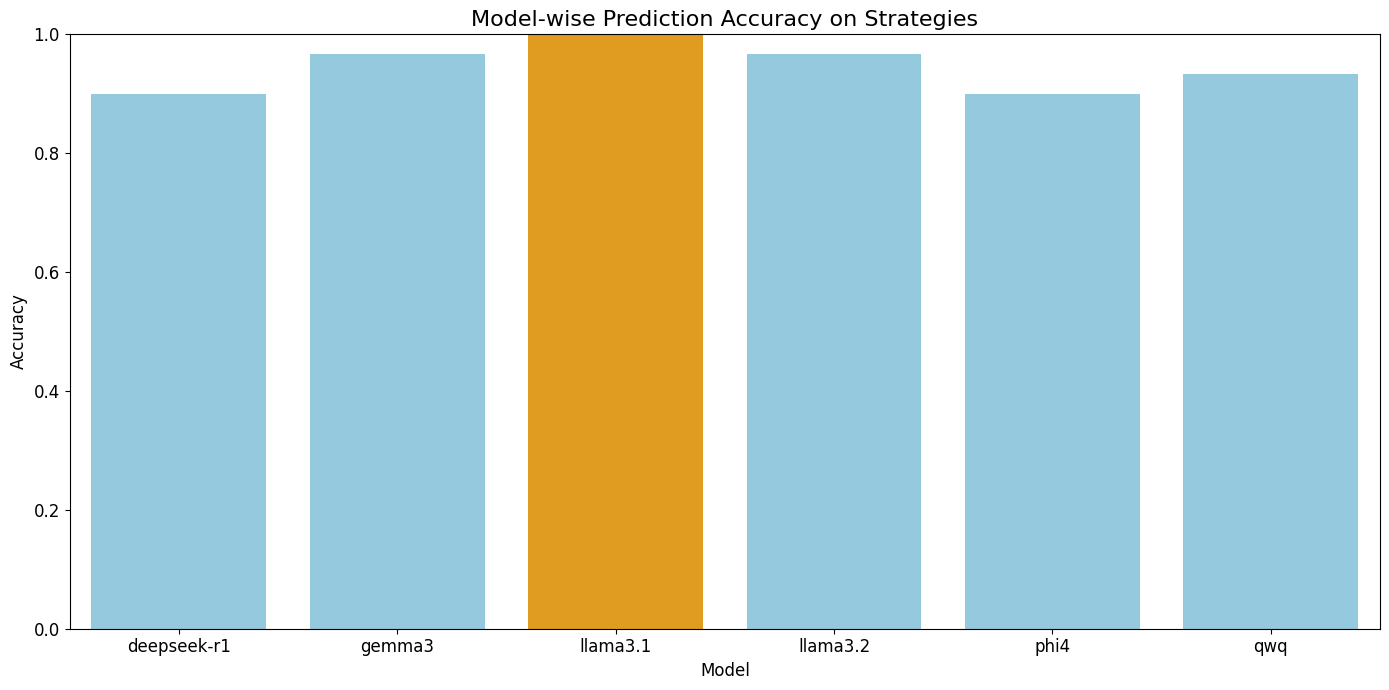

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13
point_size = 100  # mostly relevant for scatter plots

# --- data prep ---
df["total_time"] = df["time_taken"].apply(lambda x: x.total_seconds())
df["is_correct"] = df["actual"] == df["predicted"]
accuracy_df = df.groupby("model")["is_correct"].mean().reset_index()
accuracy_df.rename(columns={"is_correct": "accuracy"}, inplace=True)

# --- color mapping ---
colors = ["orange" if model == "llama3.1" else "skyblue" for model in accuracy_df["model"]]

# --- plot ---
plt.figure(figsize=(14, 7))
sns.barplot(data=accuracy_df, x="model", y="accuracy", palette=colors)

# apply font sizes
plt.title("Model-wise Prediction Accuracy on Strategies", fontsize=title_fs)
plt.xlabel("Model", fontsize=label_fs)
plt.ylabel("Accuracy", fontsize=label_fs)
plt.xticks(fontsize=tick_fs)
plt.yticks(fontsize=tick_fs)

# limits
plt.ylim(0, 1.0)

plt.tight_layout()
plt.show()


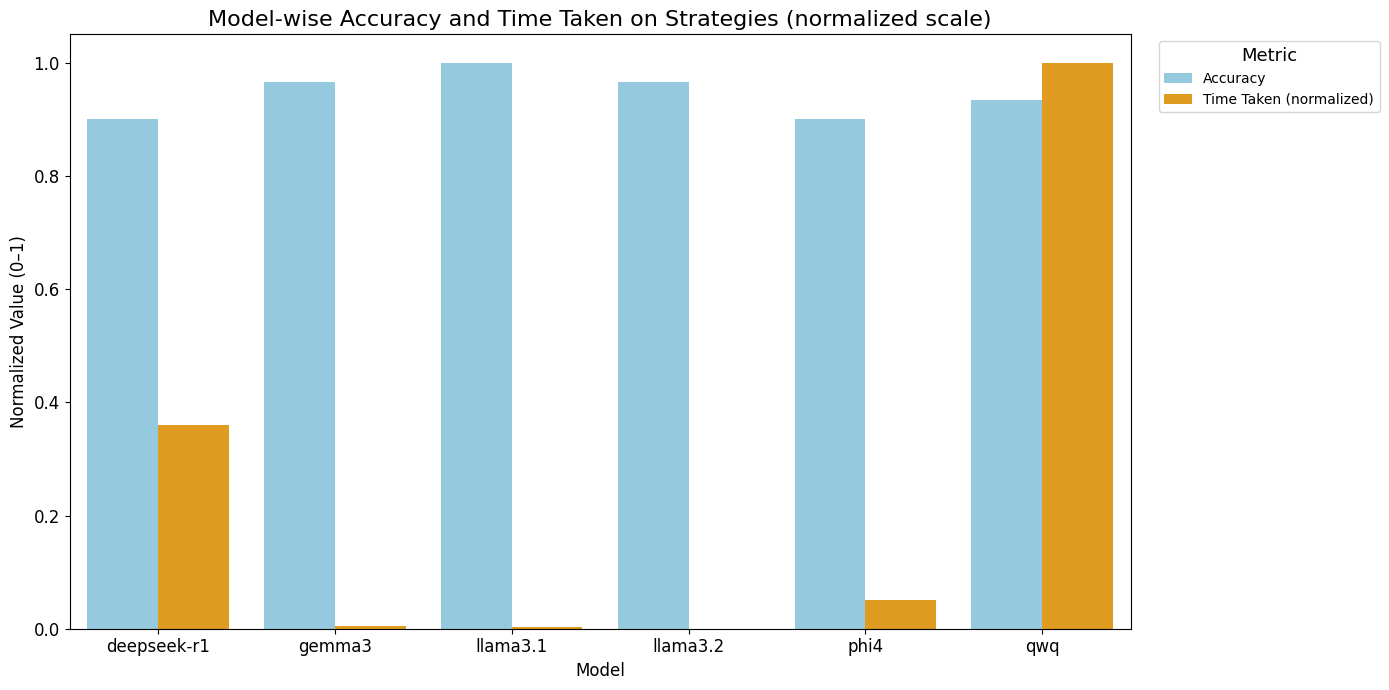

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13

# --- data prep ---
df["total_time"] = df["time_taken"].apply(lambda x: x.total_seconds())
df["is_correct"] = df["actual"] == df["predicted"]

accuracy_df = df.groupby("model")["is_correct"].mean().reset_index()
accuracy_df.rename(columns={"is_correct": "accuracy"}, inplace=True)

time_df = df.groupby("model")["total_time"].mean().reset_index()
time_df.rename(columns={"total_time": "time_taken"}, inplace=True)

# Merge both
combined_df = pd.merge(accuracy_df, time_df, on="model")

# Normalize time_taken to 0–1 scale
combined_df["time_taken_norm"] = (
    (combined_df["time_taken"] - combined_df["time_taken"].min()) /
    (combined_df["time_taken"].max() - combined_df["time_taken"].min())
)

# Melt into long format for grouped barplot
plot_df = combined_df.melt(id_vars="model", 
                           value_vars=["accuracy", "time_taken_norm"],
                           var_name="metric", value_name="value")

# Rename metrics for readability
plot_df["metric"] = plot_df["metric"].replace({
    "accuracy": "Accuracy",
    "time_taken_norm": "Time Taken (normalized)"
})

# --- color mapping ---
palette = {"Accuracy": "skyblue", "Time Taken (normalized)": "orange"}

# --- plot ---
plt.figure(figsize=(14, 7))
sns.barplot(data=plot_df, x="model", y="value", hue="metric", palette=palette)

# Apply font sizes
plt.title("Model-wise Accuracy and Time Taken on Strategies (normalized scale)", fontsize=title_fs)
plt.xlabel("Model", fontsize=label_fs)
plt.ylabel("Normalized Value (0–1)", fontsize=label_fs)
plt.xticks(fontsize=tick_fs)
plt.yticks(fontsize=tick_fs)

# Legend formatting
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left",
          fontsize=10, title_fontsize=13)
plt.tight_layout()
plt.show()


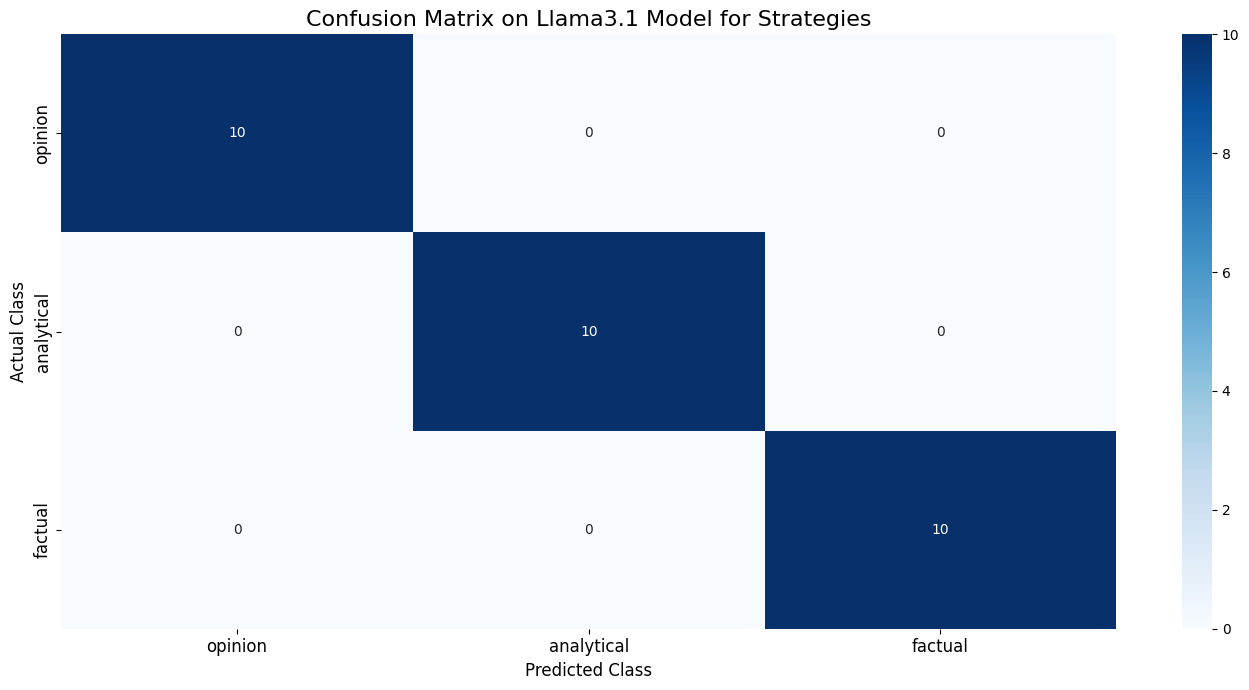

In [73]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13
point_size = 100  # mostly relevant for scatter plots

# --- confusion matrix ---
labels = llama_df['actual'].unique()
cm = confusion_matrix(llama_df['actual'], llama_df['predicted'], labels=labels)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(14, 7))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')

# Apply config
plt.title("Confusion Matrix on Llama3.1 Model for Strategies", fontsize=title_fs)
plt.xlabel("Predicted Class", fontsize=label_fs)
plt.ylabel("Actual Class", fontsize=label_fs)
plt.xticks(fontsize=tick_fs)
plt.yticks(fontsize=tick_fs)

plt.tight_layout()
plt.show()


/tmp/ipykernel_3264/4274080886.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=accuracy_df, x="model", y="accuracy", palette="viridis")


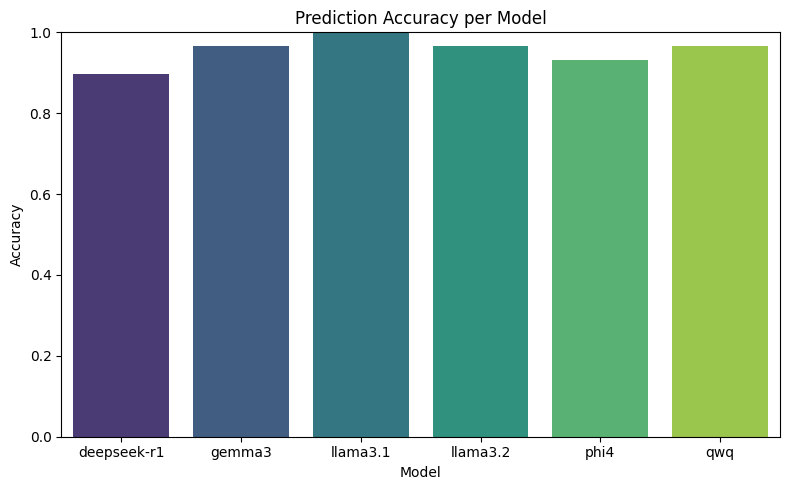

In [213]:
import seaborn as sns
import matplotlib.pyplot as plt

df["total_time"] = df["time_taken"].apply(lambda x: x.total_seconds())
df["is_correct"] = df["actual"] == df["predicted"]
accuracy_df = df.groupby("model")["is_correct"].mean().reset_index()
accuracy_df.rename(columns={"is_correct": "accuracy"}, inplace=True)

plt.figure(figsize=(8, 5))
sns.barplot(data=accuracy_df, x="model", y="accuracy", palette="viridis")
plt.title("Prediction Accuracy per Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [69]:
llama_df = df[df["model"] == "llama3.1"]


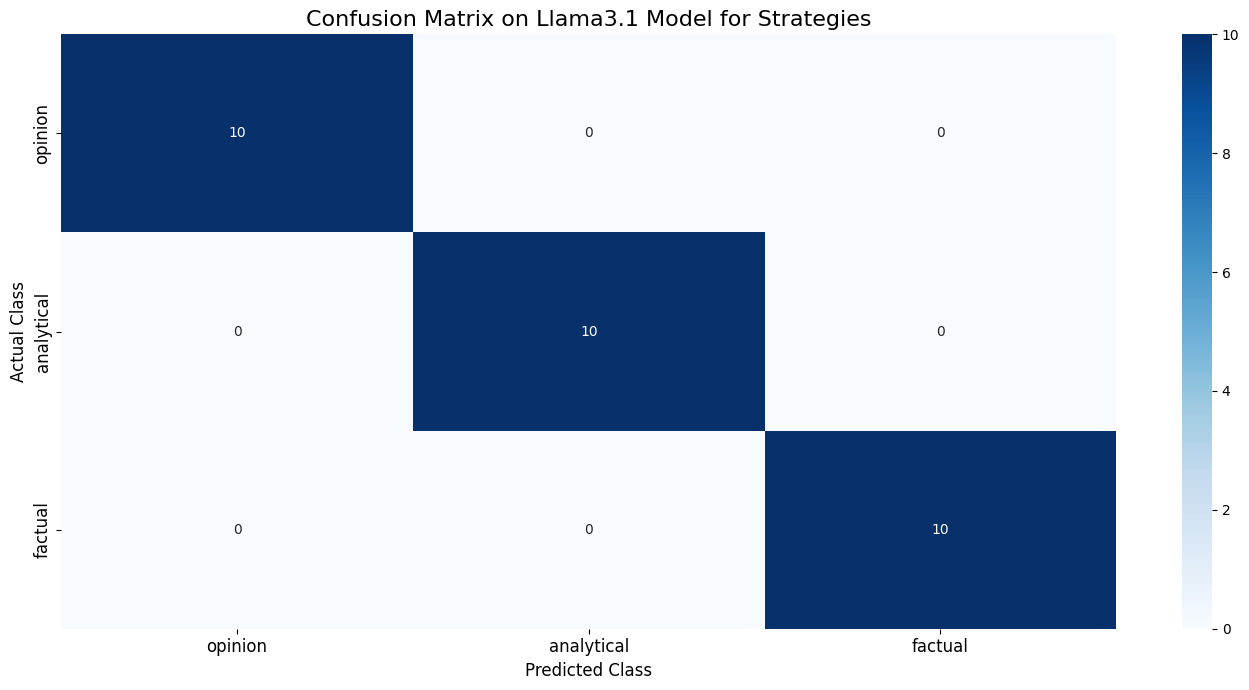

In [70]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13
point_size = 100  # mostly relevant for scatter plots

# --- confusion matrix ---
labels = llama_df['actual'].unique()
cm = confusion_matrix(llama_df['actual'], llama_df['predicted'], labels=labels)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)

plt.figure(figsize=(14, 7))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')

# Apply config
plt.title("Confusion Matrix on Llama3.1 Model for Strategies", fontsize=title_fs)
plt.xlabel("Predicted Class", fontsize=label_fs)
plt.ylabel("Actual Class", fontsize=label_fs)
plt.xticks(fontsize=tick_fs)
plt.yticks(fontsize=tick_fs)

plt.tight_layout()
plt.show()


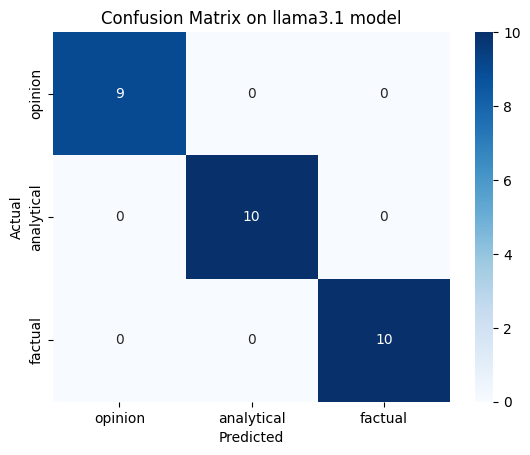

In [ ]:
from sklearn.metrics import confusion_matrix


labels = llama_df['actual'].unique()
cm = confusion_matrix(llama_df['actual'], llama_df['predicted'], labels=labels)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)

sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix on llama3.1 model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- config ---
title_fs = 16
label_fs = 12
tick_fs = 12
legend_fs = 10
legend_title_fs = 13
point_size = 100  # mostly relevant for scatter plots

# --- example plotting ---
plt.figure(figsize=(14, 7))
sns.barplot(data=llama_df, x="strategy", y="time_taken", palette="viridis")

# Apply config
plt.title("Time Taken on Llama3.1 Model on Strategies", fontsize=title_fs)
plt.xlabel("Strategy", fontsize=label_fs)
plt.ylabel("Time Taken (s)", fontsize=label_fs)
plt.xticks(fontsize=tick_fs)
plt.yticks(fontsize=tick_fs)

plt.tight_layout()
plt.show()


ValueError: Could not interpret value `strategy` for `x`. An entry with this name does not appear in `data`.

<Figure size 1400x700 with 0 Axes>

/tmp/ipykernel_3264/884310858.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=llama_df, x="actual", y="total_time", palette="viridis")


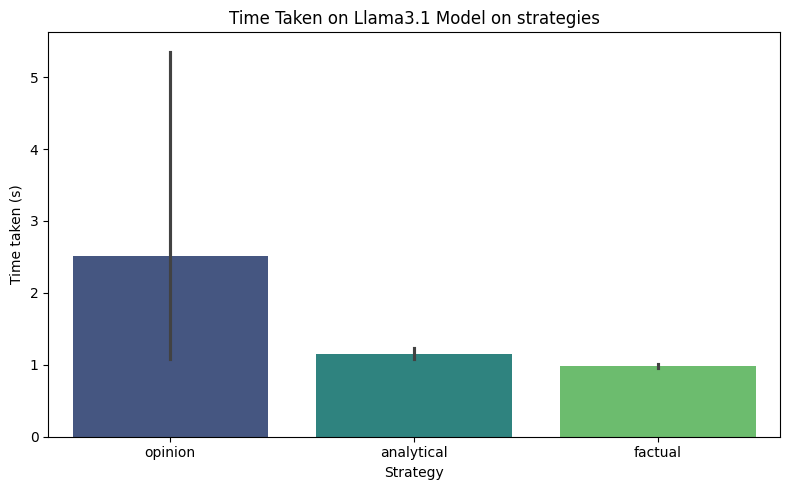

In [217]:
plt.figure(figsize=(8, 5))
sns.barplot(data=llama_df, x="actual", y="total_time", palette="viridis")
plt.title("Time Taken on Llama3.1 Model on strategies")
plt.ylabel("Time taken (s)")
plt.xlabel("Strategy")
plt.tight_layout()
plt.show()

/tmp/ipykernel_3264/542551091.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_correct", palette="Set2")


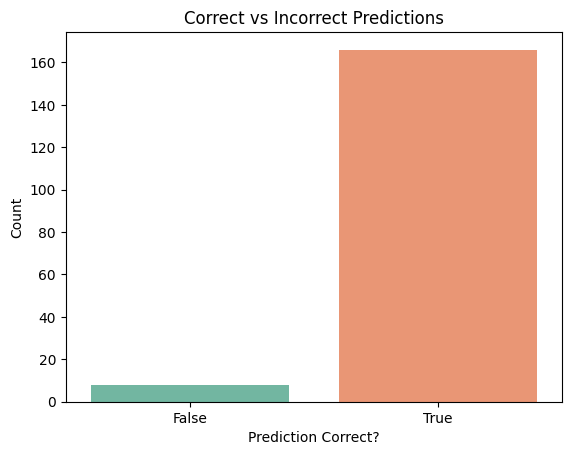

In [146]:
df["is_correct"] = df["actual"] == df["predicted"]

sns.countplot(data=df, x="is_correct", palette="Set2")
plt.title("Correct vs Incorrect Predictions")
plt.xlabel("Prediction Correct?")
plt.ylabel("Count")
plt.show()